# Лабораторная работа №1. Численное дифференцирование

## 1. Постановка задачи

**Задача:** вычислить производные пяти функций в точке $x_0$ пятью
разностными формулами и исследовать абсолютную погрешность при
$h_n=2/2^n$, $n=1,\ldots,21$.

Параметры меняются в следующей ячейке. Выполняйте ячейки сверху вниз
или выберите **Restart Kernel and Run All Cells**. Все вычислительные
методы реализованы обычными функциями; NumPy используется для массивов.

## 2. Библиотеки и параметры

Измените исходные данные ниже и выполните тетрадь сверху вниз.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Keep the point positive so every logarithm and square-root stencil is valid.
x0 = 2.0
if not np.isfinite(x0) or x0 <= 0:
    raise ValueError("x0 must be a finite positive number.")

n_values = np.arange(1, 22)
h = 2.0 / 2.0**n_values

## 3. Теория и методы

### Функции и точные производные

Рассматриваются $\sin(x^2)$, $\cos(\sin x)$,
$\exp(\sin(\cos x))$, $\ln(x+3)$ и $\sqrt{x+3}$.
Их аналитические производные нужны только для вычисления погрешности.

In [ ]:
# Analytical derivatives provide independent reference values.
def f1(x):
    return np.sin(x**2)

def df1(x):
    return 2 * x * np.cos(x**2)

def f2(x):
    return np.cos(np.sin(x))

def df2(x):
    return -np.sin(np.sin(x)) * np.cos(x)

def f3(x):
    return np.exp(np.sin(np.cos(x)))

def df3(x):
    return -np.exp(np.sin(np.cos(x))) * np.cos(np.cos(x)) * np.sin(x)

def f4(x):
    return np.log(x + 3)

def df4(x):
    return 1 / (x + 3)

def f5(x):
    return np.sqrt(x + 3)

def df5(x):
    return 0.5 / np.sqrt(x + 3)

functions = [
    {"name": "sin(x^2)", "file": "sin_x2", "f": f1, "df": df1},
    {"name": "cos(sin(x))", "file": "cos_sin_x", "f": f2, "df": df2},
    {"name": "exp(sin(cos(x)))", "file": "exp_sin_cos_x", "f": f3, "df": df3},
    {"name": "ln(x+3)", "file": "ln_x_plus_3", "f": f4, "df": df4},
    {"name": "sqrt(x+3)", "file": "sqrt_x_plus_3", "f": f5, "df": df5},
]

### Разностные формулы

Из разложения Тейлора получаются правая и левая разности первого порядка:
$$D_1=\frac{f(x+h)-f(x)}h,\qquad D_2=\frac{f(x)-f(x-h)}h.$$
Центральная разность $\delta(h)=[f(x+h)-f(x-h)]/(2h)$ имеет порядок $O(h^2)$.
Комбинации $D_4=\frac43\delta(h)-\frac13\delta(2h)$ и
$D_5=\frac32\delta(h)-\frac35\delta(2h)+\frac1{10}\delta(3h)$
исключают ведущие члены погрешности и дают порядки $O(h^4)$ и $O(h^6)$.

In [ ]:
# One-sided differences retain the leading O(h) truncation term.
def forward_difference(f, x, h):
    return (f(x + h) - f(x)) / h

def backward_difference(f, x, h):
    return (f(x) - f(x - h)) / h

# Symmetry cancels odd powers in the numerator's Taylor expansion.
def central_difference(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

def fourth_order_difference(f, x, h):
    return (4 * central_difference(f, x, h) - central_difference(f, x, 2 * h)) / 3

def sixth_order_difference(f, x, h):
    return (1.5 * central_difference(f, x, h)
            - 0.6 * central_difference(f, x, 2 * h)
            + 0.1 * central_difference(f, x, 3 * h))

methods = [
    {"name": "Forward: O(h)", "function": forward_difference},
    {"name": "Backward: O(h)", "function": backward_difference},
    {"name": "Central: O(h^2)", "function": central_difference},
    {"name": "Fourth order: O(h^4)", "function": fourth_order_difference},
    {"name": "Sixth order: O(h^6)", "function": sixth_order_difference},
]

## 4. Расчёты и графики

### Погрешность и графики

Вычисляем $\varepsilon=|D(h)-f'(x_0)|$. На графике в логарифмических
осях наклон при преобладании погрешности метода близок к его порядку.
При очень малом шаге ошибки округления могут остановить уменьшение ошибки:
$\varepsilon\approx C_ph^p+M\varepsilon_{mach}/h$.
Нулевая вычисленная ошибка пропускается на логарифмическом графике.

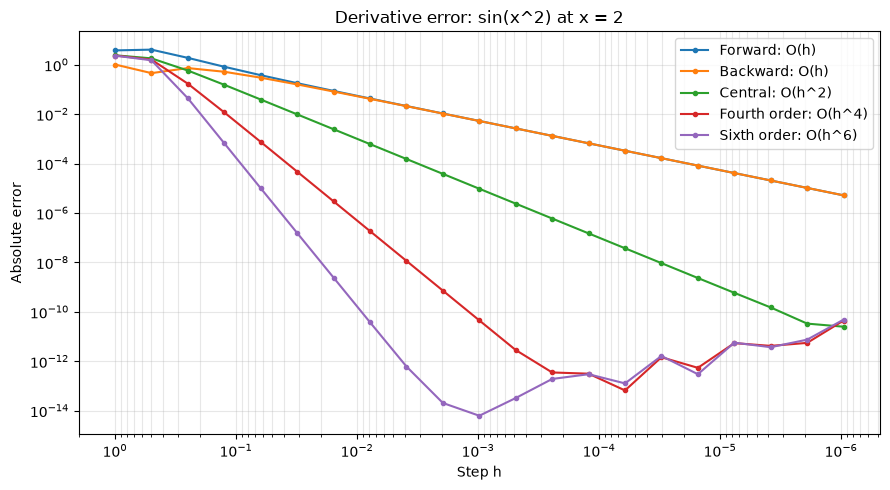

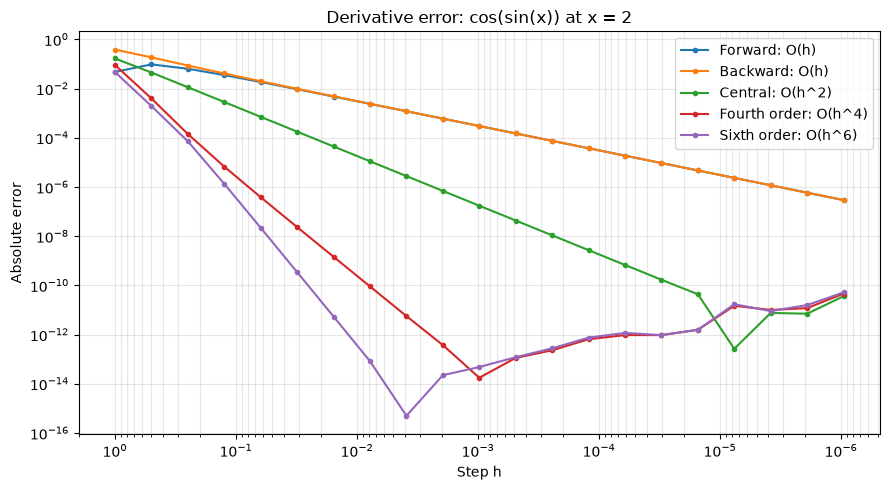

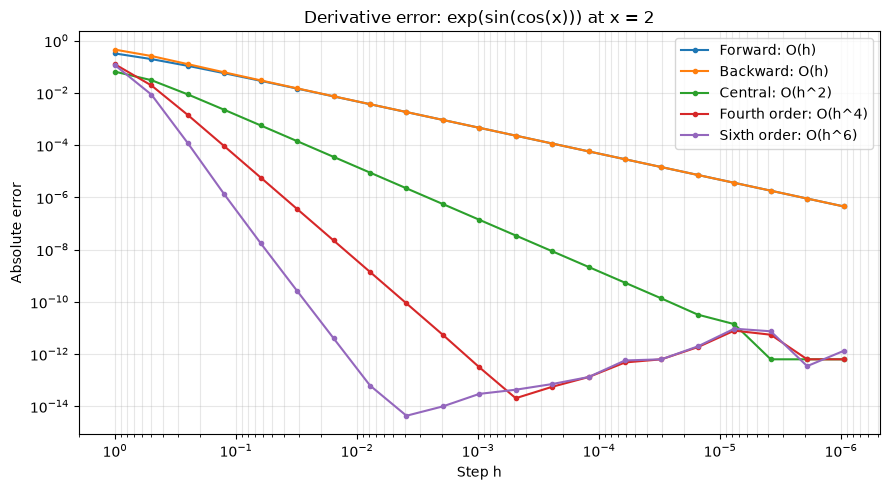

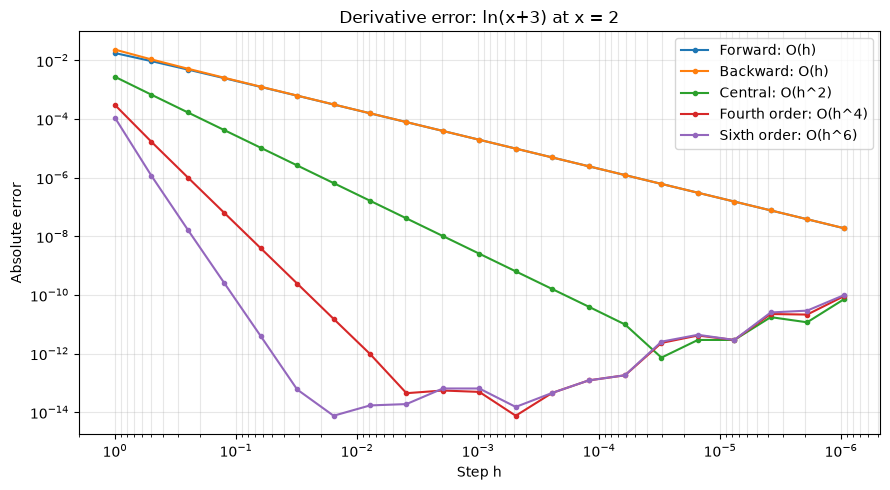

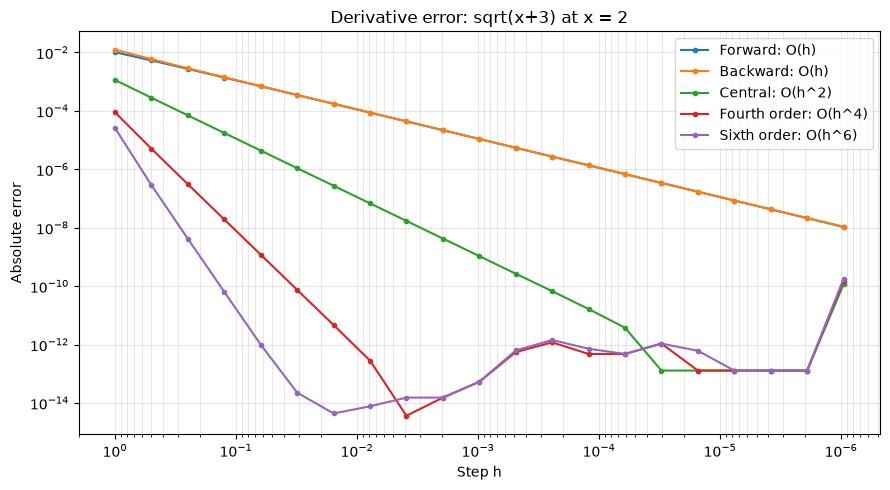

In [ ]:
for item in functions:
    fig, ax = plt.subplots(figsize=(9, 5))
    exact = item["df"](x0)
    for method in methods:
        approximation = method["function"](item["f"], x0, h)
        error = np.abs(approximation - exact)
        # Zero has no logarithm; leave the numerical error unchanged.
        plotted_error = np.where(error > 0, error, np.nan)
        ax.loglog(h, plotted_error, marker="o", markersize=3, label=method["name"])

    ax.set_title(f"Derivative error: {item['name']} at x = {x0:g}")
    ax.set_xlabel("Step h")
    ax.set_ylabel("Absolute error")
    ax.invert_xaxis()
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 5. Проверка реализации

Проверим точность схем на полиномах и ожидаемое уменьшение погрешности
центральной разности при делении шага пополам. На исходной сетке из 21 шага
минимум ошибки может лежать за пределами исследуемого диапазона.

In [ ]:
# Polynomial derivatives are exact references, independent of the test functions.
np.testing.assert_allclose(central_difference(lambda x: x**2, 2.0, 0.1), 4.0)
np.testing.assert_allclose(fourth_order_difference(lambda x: x**4, 2.0, 0.1), 32.0)
np.testing.assert_allclose(sixth_order_difference(lambda x: x**6, 2.0, 0.1), 192.0)
coarse_error = abs(central_difference(np.sin, 1.0, 0.1) - np.cos(1.0))
fine_error = abs(central_difference(np.sin, 1.0, 0.05) - np.cos(1.0))
assert 3.9 < coarse_error / fine_error < 4.1
print("All differentiation checks passed.")

All differentiation checks passed.
